# Quartz diffraction: six-component spatial strain reconstruction
These are existing author-supplied simulated observations, not real experimental measurements. A known support and 500 directional diffraction events constrain a six-component symmetric tensor field. The complete selected scope is the paper strain reconstruction demonstration, rather than its separate coupled orientation extension.

The acquisition is b=k^T <E> k+noise, with <E> the support-normalized Joseph line integral, k the measured diffraction direction, and dimensionless strain E. Off-diagonal contractions have factors two. The Gaussian basis renderer B, six directional weights S, normalized projection P and precision W yield A=WSPB. The objective is the unnormalized sum ||Aa-Wb||^2, initialized at zero and minimized by the original effective L-BFGS-B tolerance1e-8 and maximum390 iterations.

The source GPU backprojection is not the transpose of its forward projector. This task explicitly corrects its gradient to the matched RBF Jacobian transpose while retaining the original forward, data, basis, optimizer and stopping. It does not claim unchanged reproduction. Original GPU/CPU results and the corrected oracle remain distinctly identified. The visible local CUDA kernel uses general runtime primitives and no ASTRA package or binary.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import make_figures,export_figures,component_metrics
from src.cuda_runtime import close_runtime
assert importlib.util.find_spec('astra') is None, 'This validation uses the cleaned environment without ASTRA'
data=load_data(root/'data/raw_data.npz')
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
start=time.perf_counter();field,diagnostics=reconstruct(data);runtime=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True);np.savez_compressed(root/'output/reconstruction.npz',reconstruction=field[None])
report=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps({'fresh_seconds':runtime,'iterations':diagnostics['iterations'],'message':diagnostics['message'],'judge':report},indent=2));assert report['passed']

{
  "fresh_seconds": 8.279311199999938,
  "iterations": 108,
  "message": "CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH",
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "xx_ncc": 0.9942767320349345,
      "xx_nrmse": 0.028540341078467837,
      "yy_ncc": 0.9995032889644005,
      "yy_nrmse": 0.020471019164044424,
      "zz_ncc": 0.9988109658254868,
      "zz_nrmse": 0.011578087609279947,
      "xy_ncc": 0.9995421944206317,
      "xy_nrmse": 0.014986728126204546,
      "xz_ncc": 0.9995133239857826,
      "xz_nrmse": 0.013357775303162896,
      "yz_ncc": 0.9996194891411626,
      "yz_nrmse": 0.010293266718433619
    },
    "thresholds": {
      "xx_ncc": {
        "comparison": ">=",
        "boundary": 0.8948490588314405
      },
      "xx_nrmse": {
        "comparison": "<=",
        "boundary": 0.03139437518631463
      },
      "yy_ncc": {
        "comparison": ">=",
        "boundary": 0.8995529600679606
      },
      "yy_nrmse": {
        "co

## Fresh convergence comparison and independently identified references
The default path reconstructs every observed ray and all six fields. The shortened run below is also computed freshly and uses maxiter20 only to illustrate convergence. Oracle arrays never substitute for either active result. The bounded matched Jacobian uses about300MB; this task does not claim to reproduce the original paper large-volume memory benchmark.

CPU strip and CPU Joseph captures are retained because a successful source import or a superficially similar projector would otherwise obscure a serious fidelity problem. The original CPU branch changes ray geometry/discretization. Even a close CPU Joseph approximation shifts texture quantization boundaries and causes much larger inverse changes. The exact local CUDA direction templates preserve the numerical sequence that the simplified kernels failed to reproduce.

Fresh default and corrected source field are bitwise equal; source gradient correction is explicitly identified.


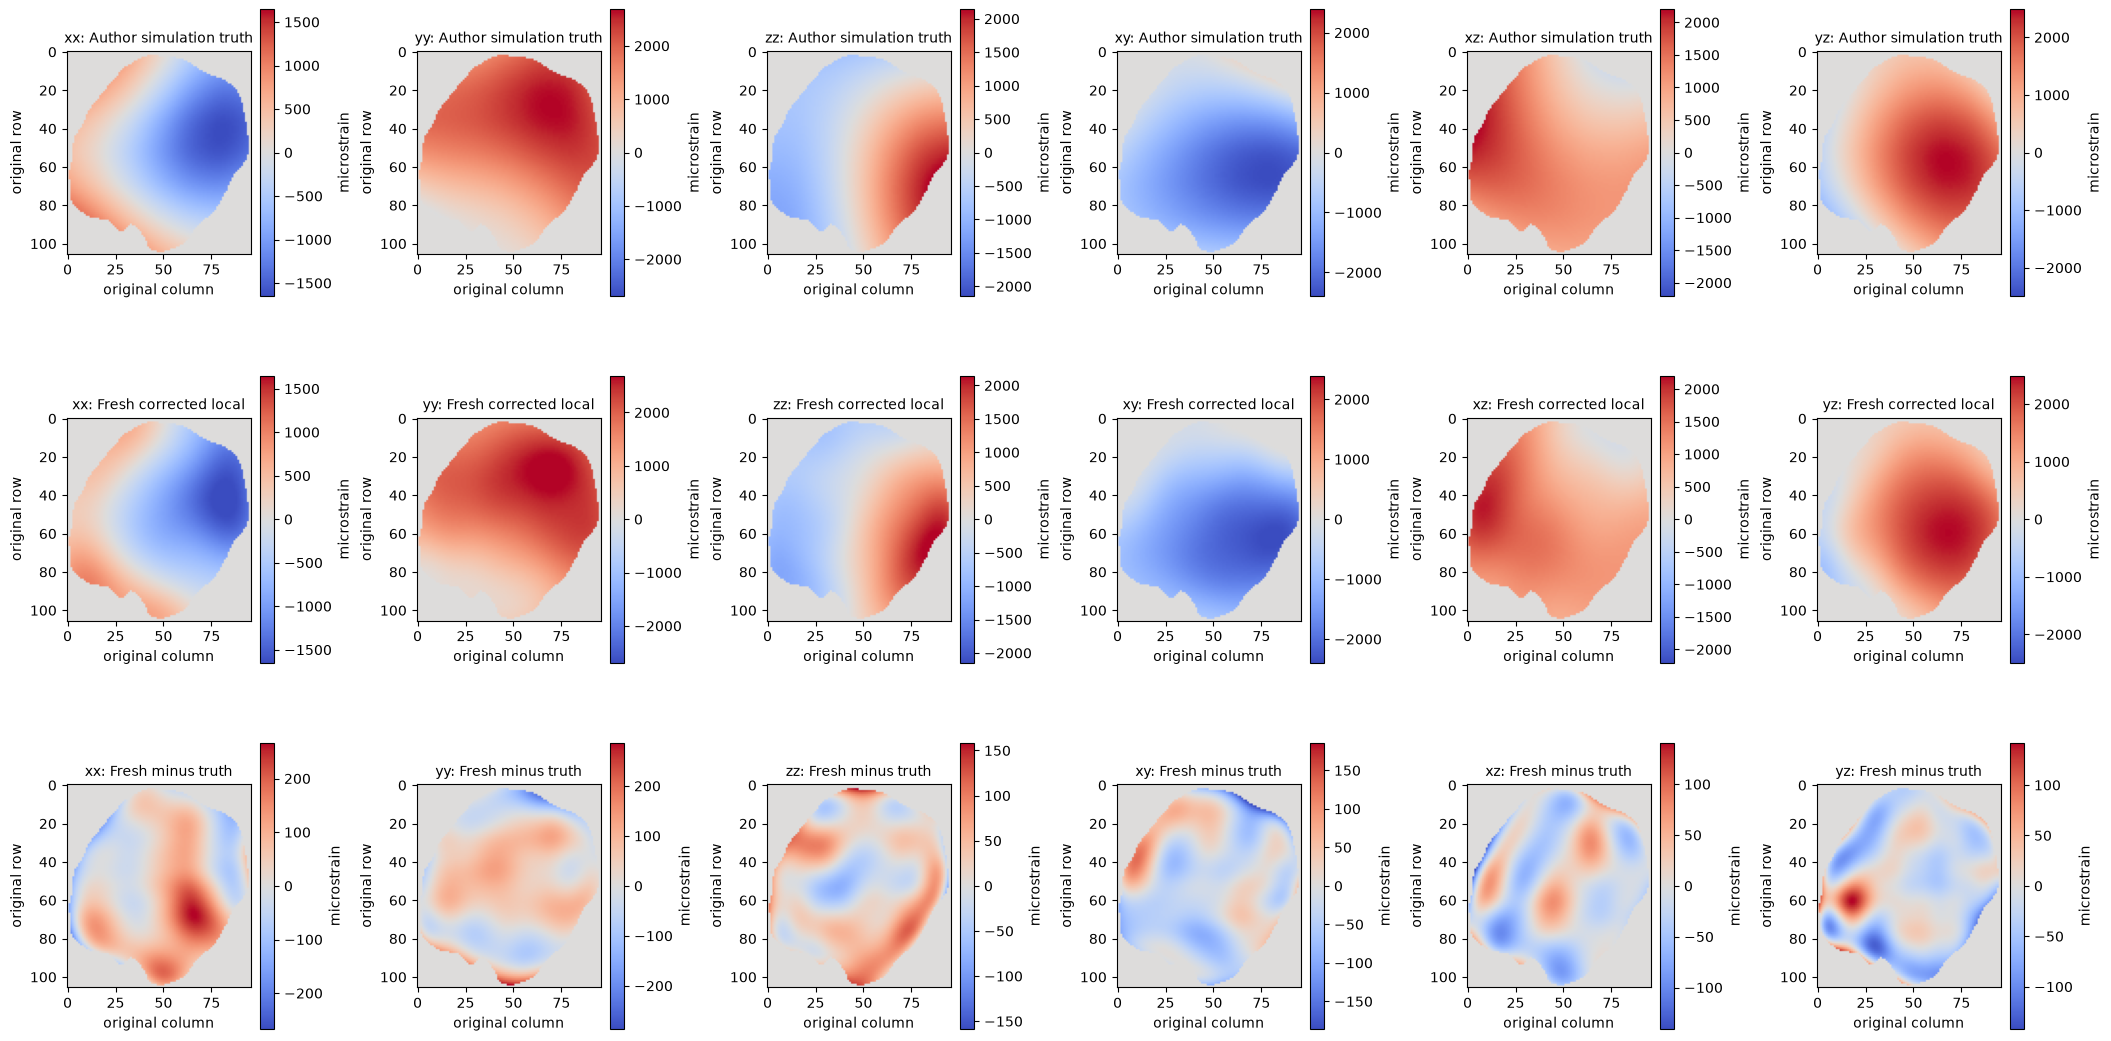

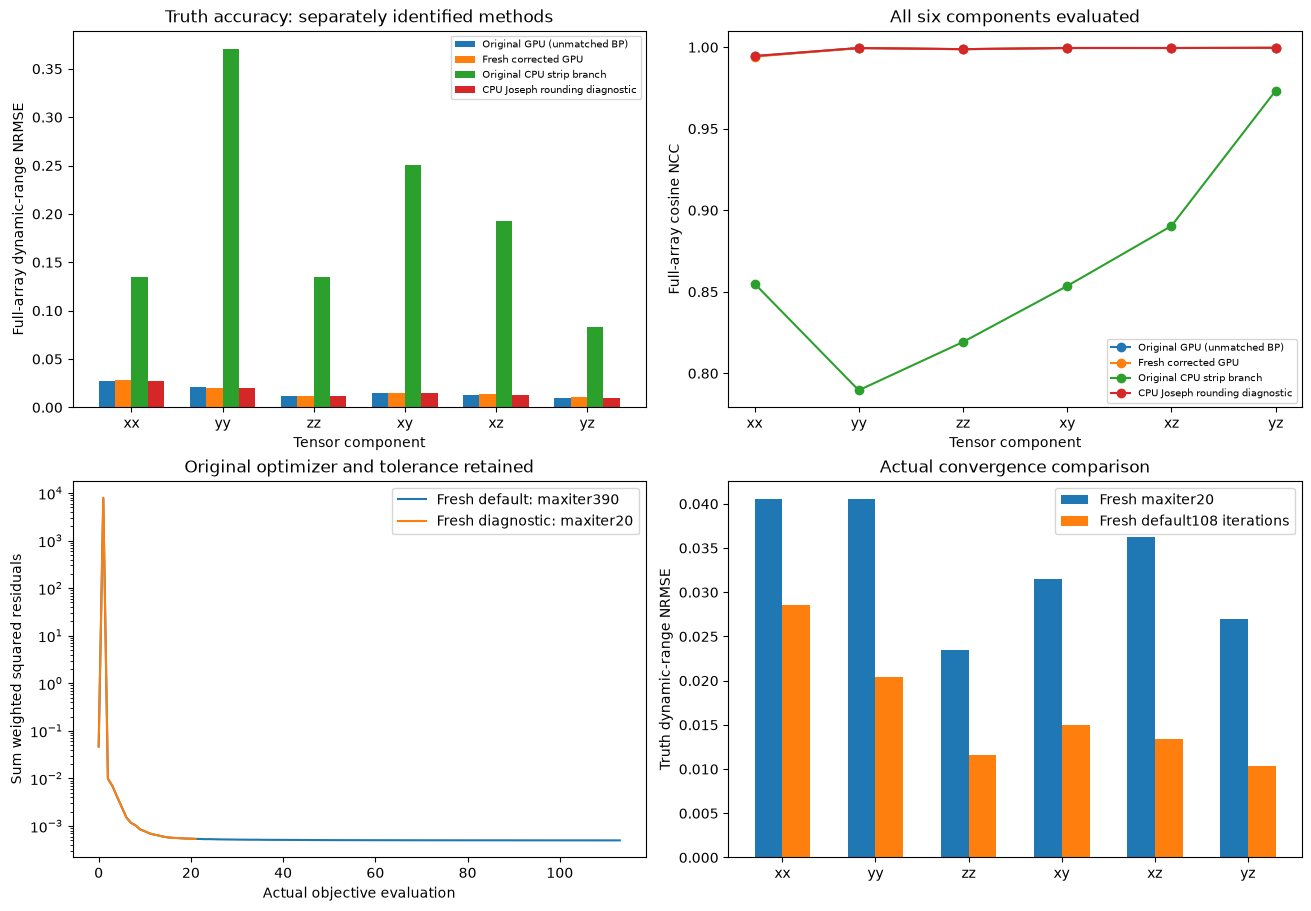

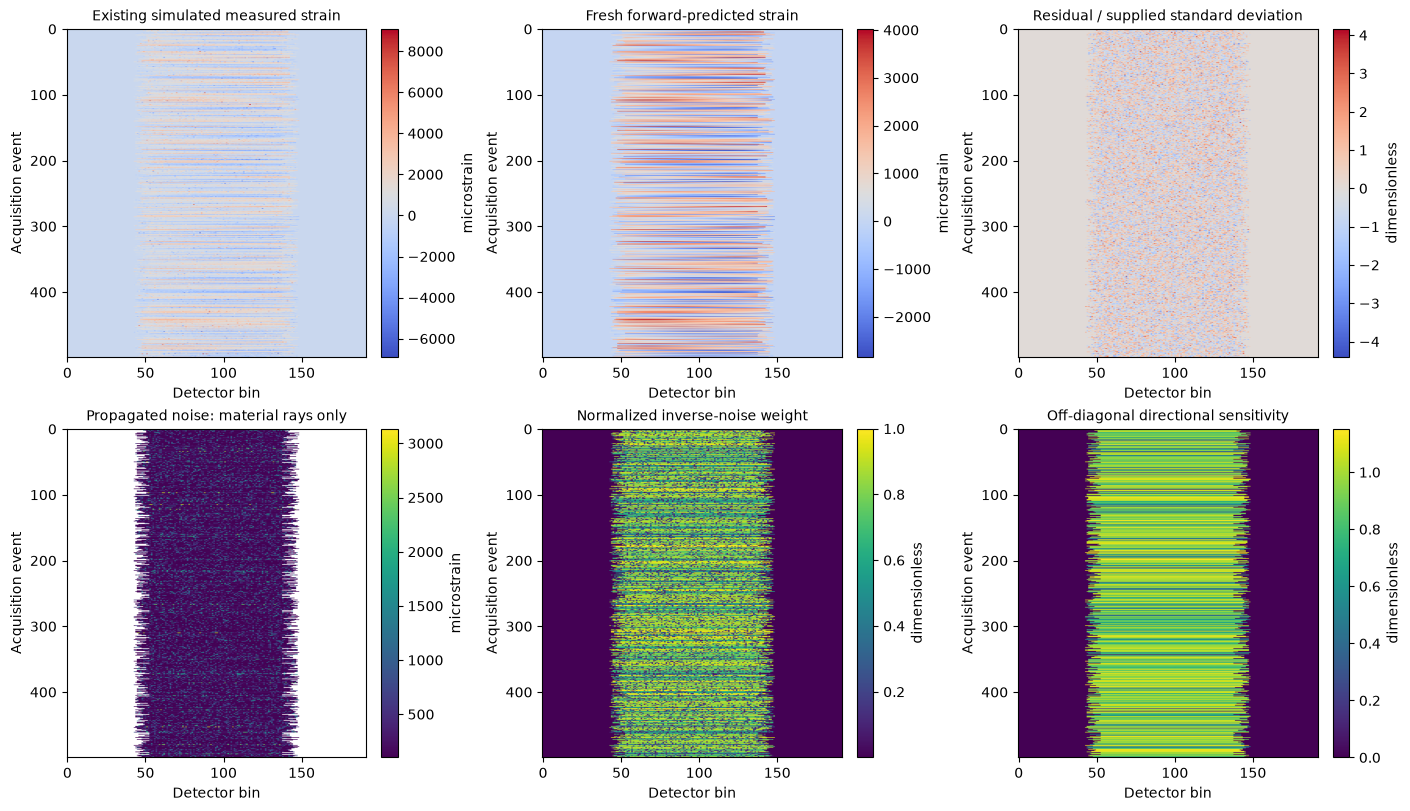

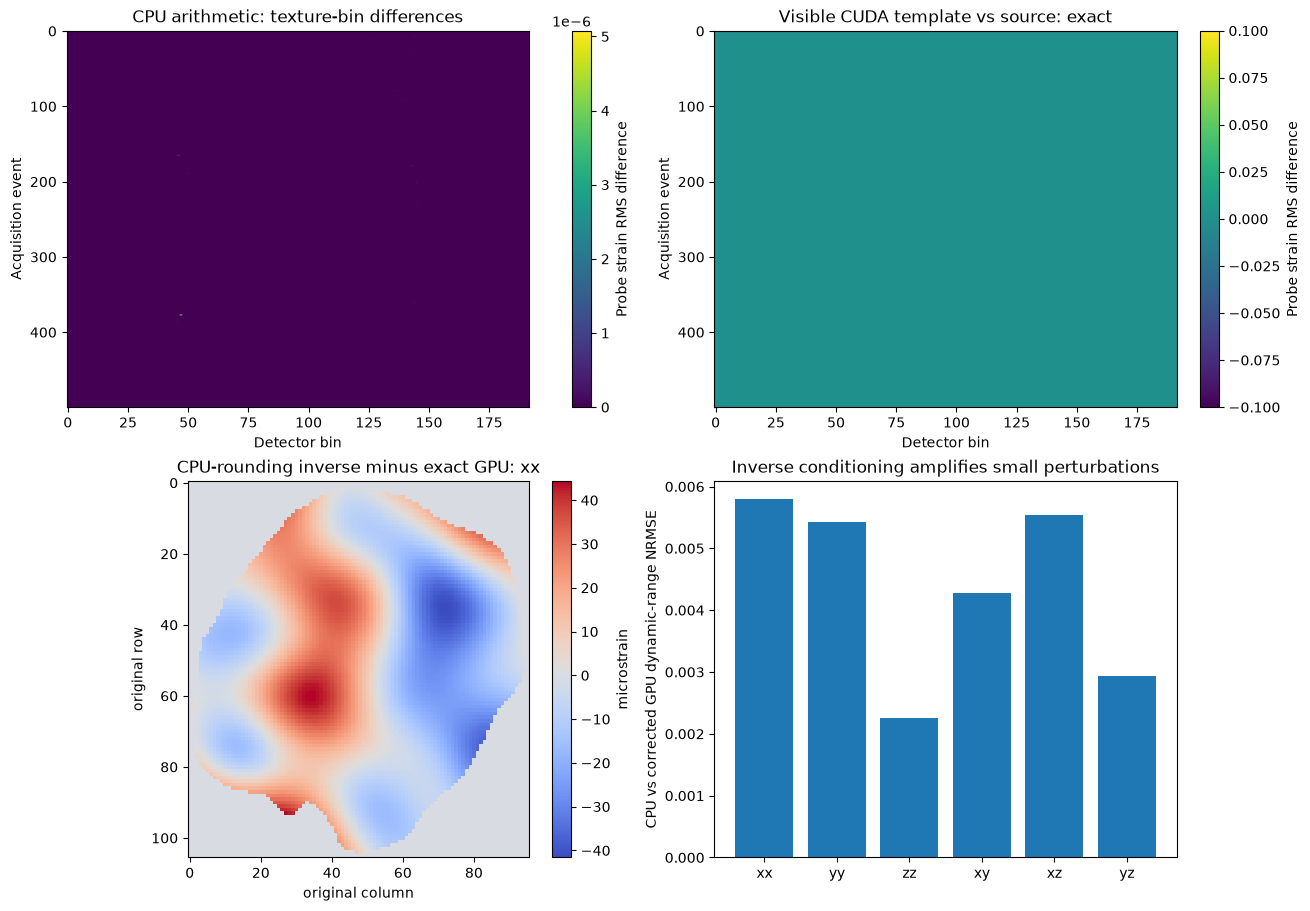

{
  "iterations": 108,
  "objective": 0.000497801428256455,
  "weighted_residual_norm": 0.022311464054527094,
  "standardized_residual_rms_inside_rays": 1.0033853617403523,
  "truth_components": [
    [
      0.9942767320349342,
      0.028540341078467844
    ],
    [
      0.9995032889644002,
      0.020471019164044413
    ],
    [
      0.9988109658254863,
      0.011578087609279947
    ],
    [
      0.9995421944206316,
      0.014986728126204545
    ],
    [
      0.9995133239857824,
      0.013357775303162896
    ],
    [
      0.999619489141162,
      0.010293266718433615
    ]
  ],
  "cpu_projection_relative_error": 2.9054190235910937e-05,
  "fresh_projection_max_error": 0.0,
  "fresh_seconds": 8.279311199999938,
  "short_fresh_seconds": 1.4251499000019976,
  "short_iterations": 20,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "xx_ncc": 0.9942767320349345,
      "xx_nrmse": 0.028540341078467837,
      "yy_ncc": 0.9995032889644005,
      "yy_nrmse

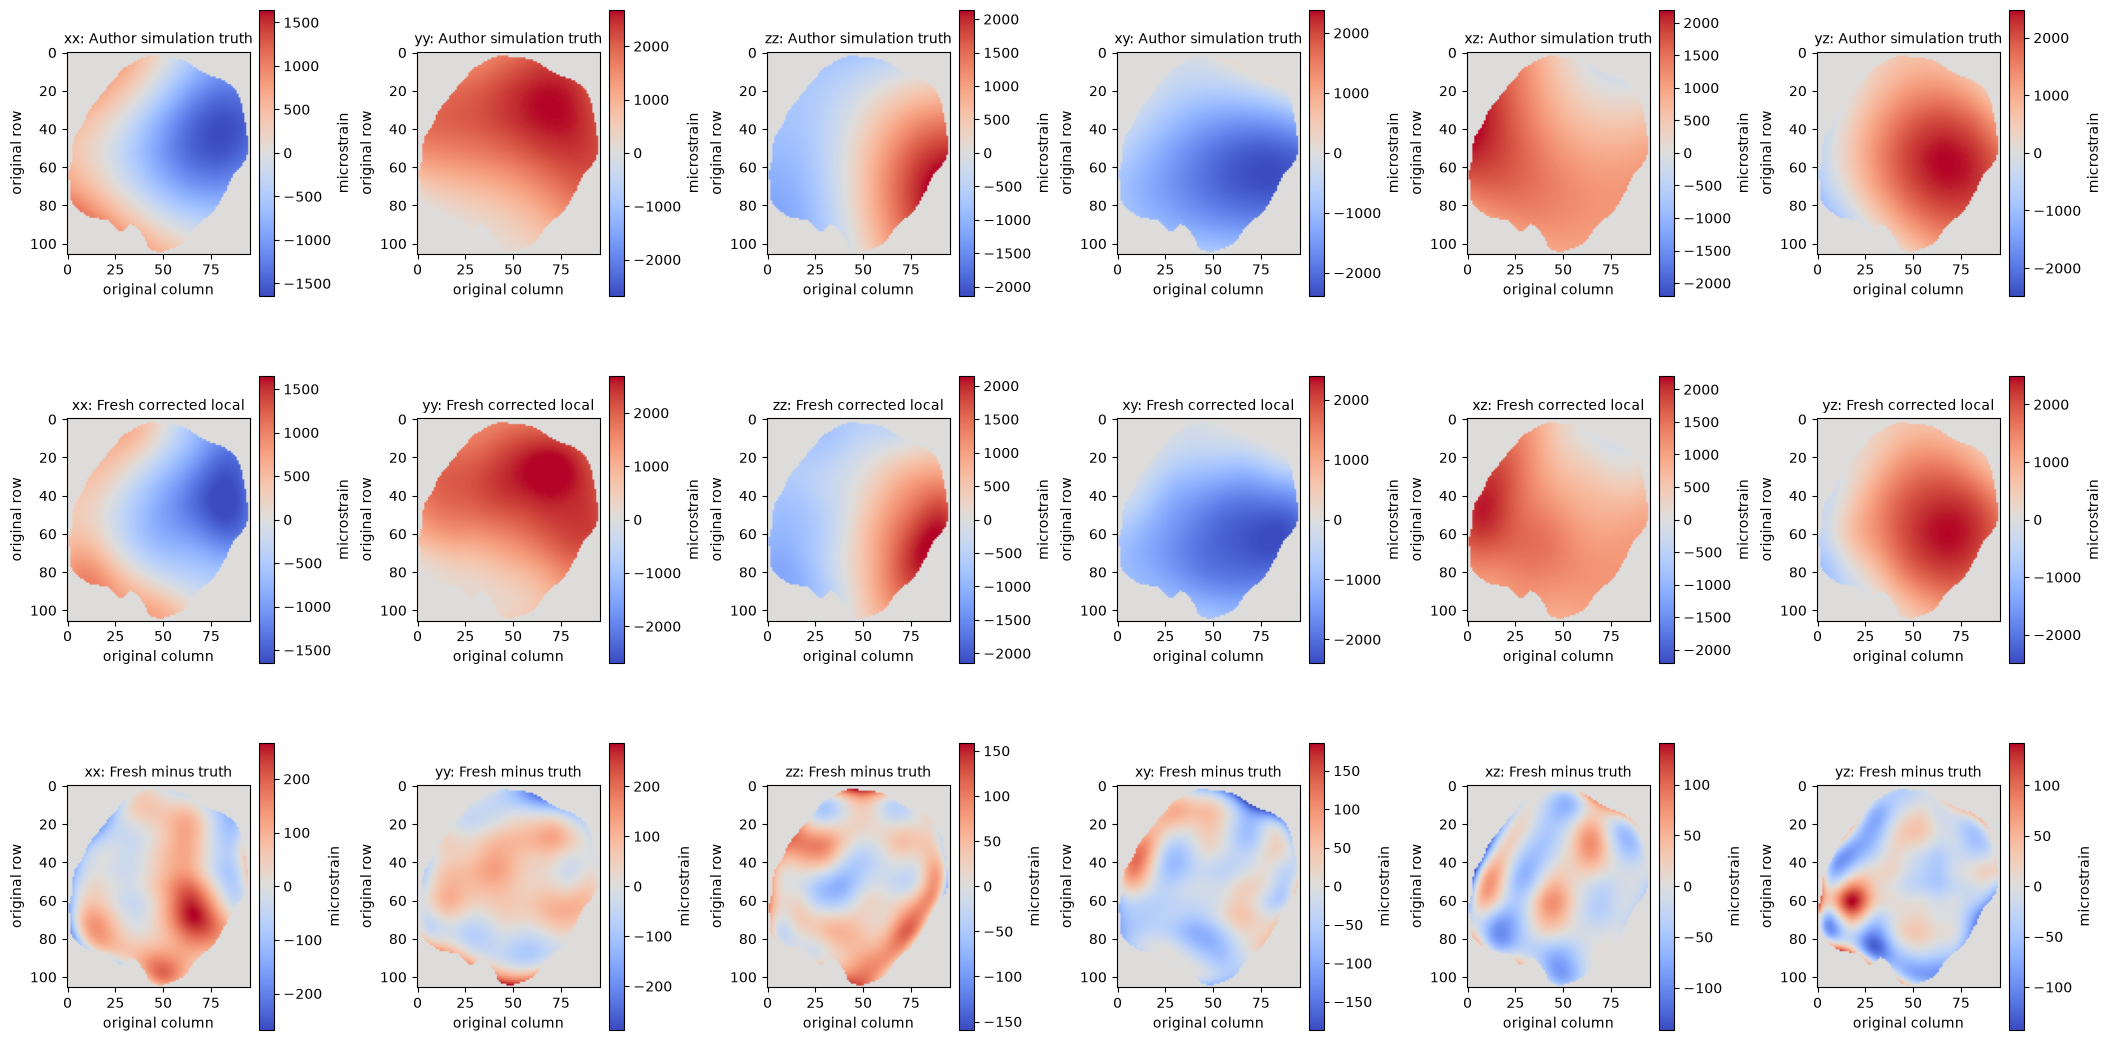

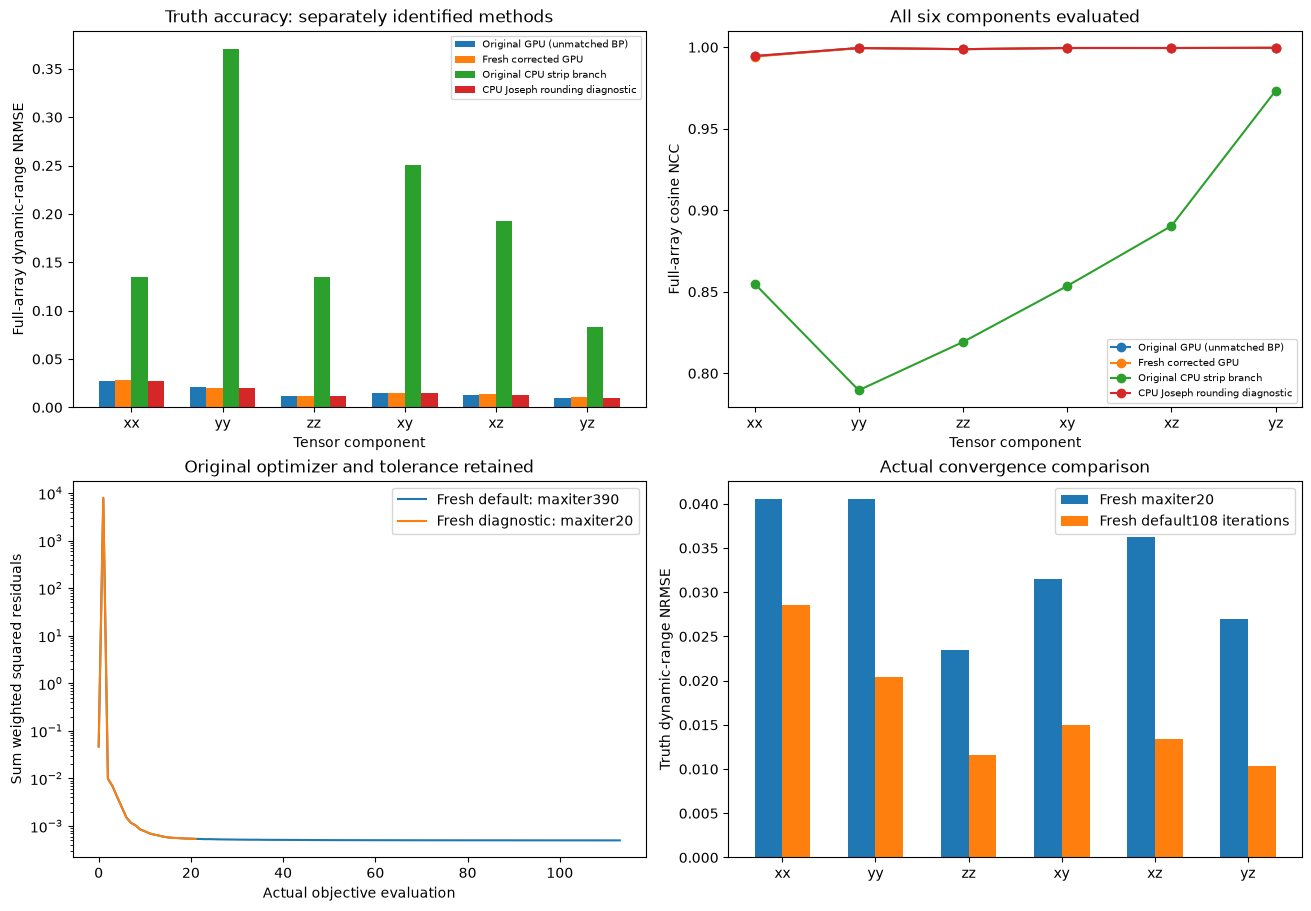

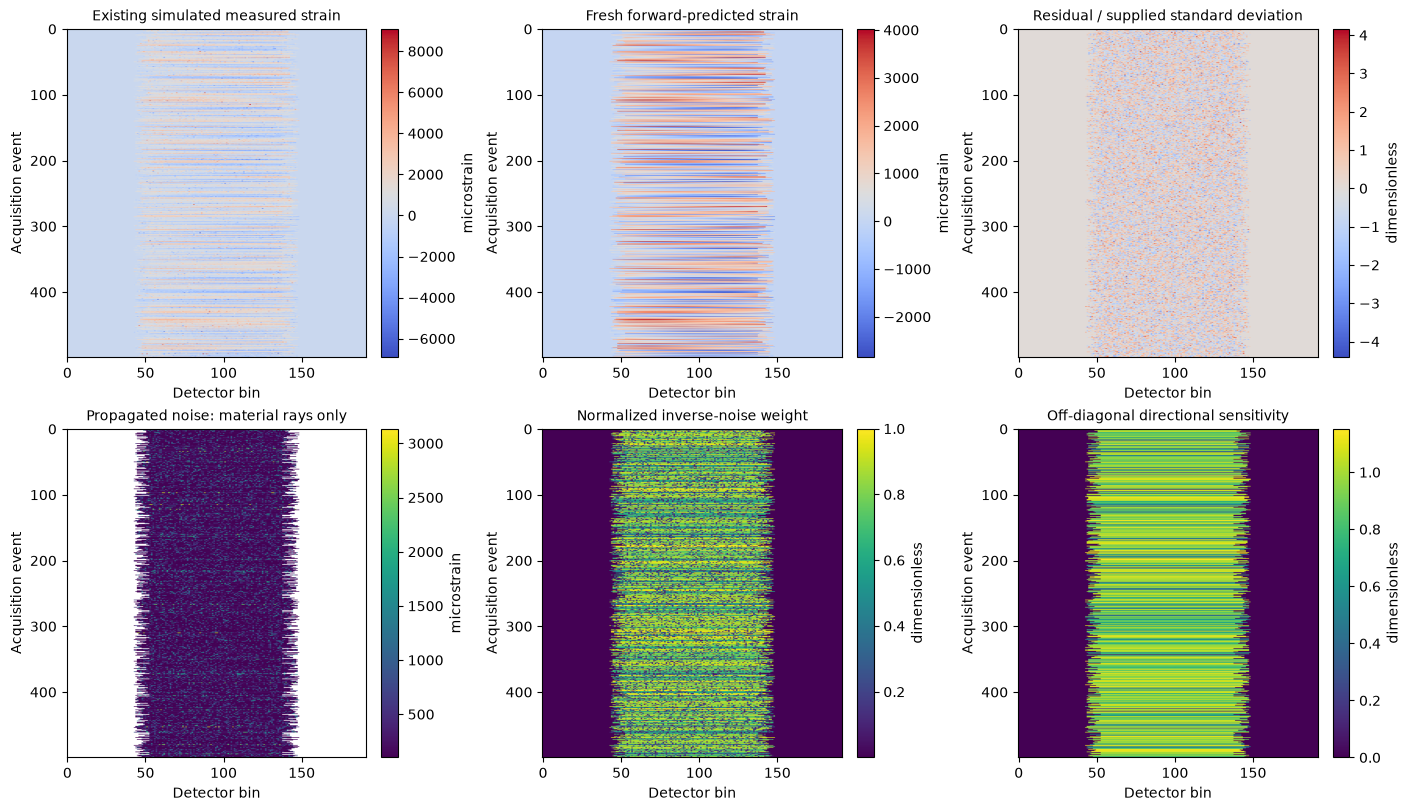

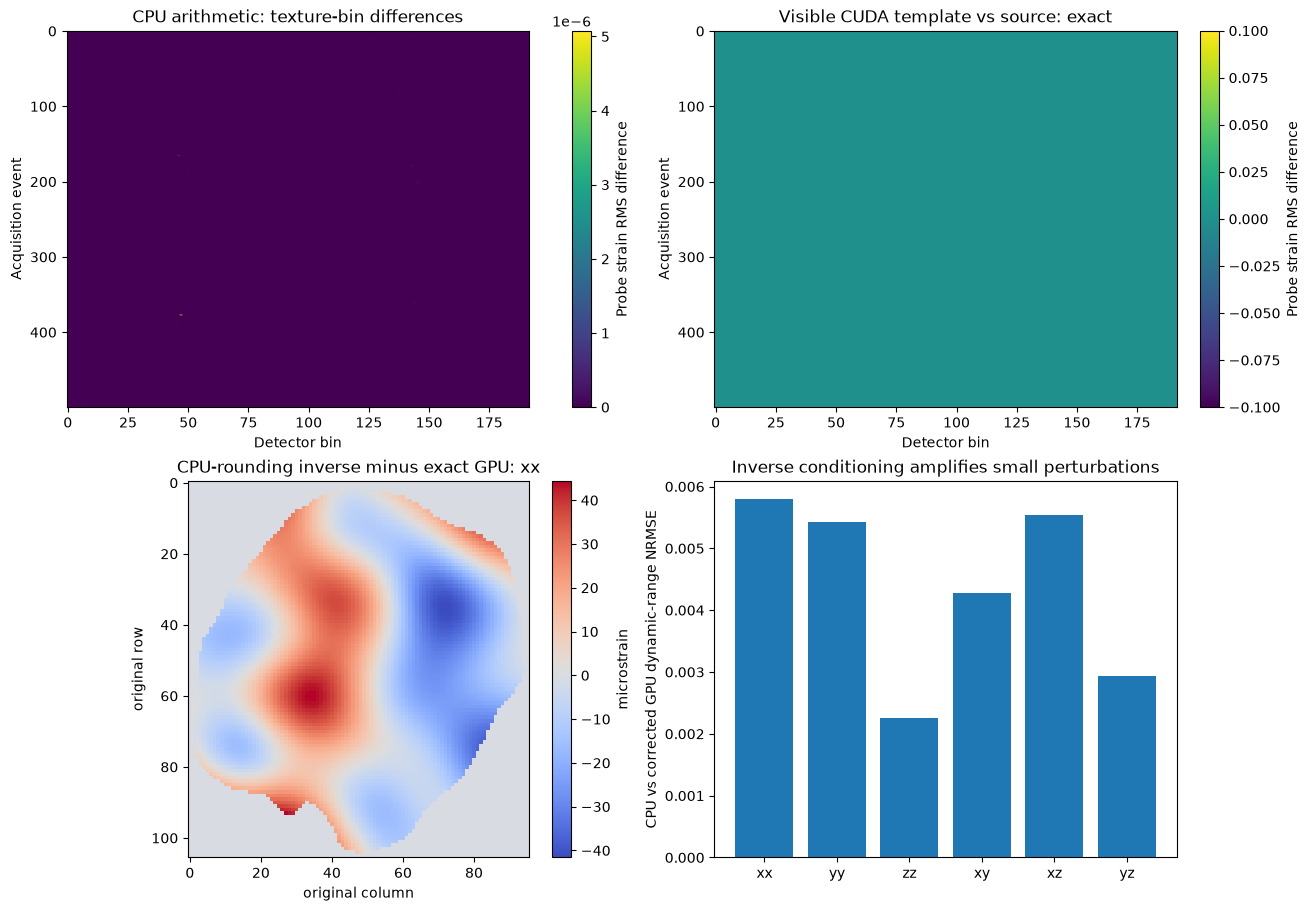

In [2]:
start=time.perf_counter();short,short_diagnostics=reconstruct(data,maxiter=20);short_runtime=time.perf_counter()-start
with np.load(root/'evaluation/ground_truth.npz') as z:truth=z['reconstruction'][0]
with np.load(root/'notebooks/reference_outputs/corrected_oracle.npz') as z:corrected=z['output_reconstruction']
with np.load(root/'notebooks/reference_outputs/uncorrected_gpu_oracle.npz') as z:original_gpu=z['output_reconstruction']
with np.load(root/'notebooks/reference_outputs/original_cpu_diagnostic.npz') as z:original_cpu=z['output_reconstruction']
with np.load(root/'notebooks/reference_outputs/cpu_rounding_diagnostic.npz') as z:cpu_rounding=z['output_reconstruction']
with np.load(root/'notebooks/reference_outputs/cpu_forward_diagnostic.npz') as z:archived_cpu_projection=z['output_projection']
from src.cpu_diagnostic import joseph_matrix
from src.physics_model import render
cpu_matrix=joseph_matrix(data['support'].shape,data['angles'],192)
cpu_density=cpu_matrix@data['support'].ravel().astype('float32')
cpu_inverse=np.divide(1,cpu_density,out=np.zeros_like(cpu_density),where=cpu_density!=0)
probe=np.sin(np.arange(390)).reshape(6,65)*.001
probe_field=render(diagnostics['model'].basis,probe,data['support'].shape)
cpu_projection=np.array([cpu_matrix@a.astype('float32').ravel()*cpu_inverse for a in probe_field]).reshape(6,500,192)
assert np.array_equal(cpu_projection,archived_cpu_projection)
del cpu_matrix
with np.load(root/'test/fixtures/upstream_stages.npz') as z:source_projection=z['output_projection']
assert np.array_equal(field,corrected)
print('Fresh default and corrected source field are bitwise equal; source gradient correction is explicitly identified.')
groups,numeric,summary=make_figures(data,field,diagnostics,truth,original_gpu,original_cpu,cpu_rounding,cpu_projection,source_projection,short,short_diagnostics)
summary.update(fresh_seconds=runtime,short_fresh_seconds=short_runtime,short_iterations=short_diagnostics['iterations'],judge=report)
for fig in groups.values():display(fig)
directory=Path(os.environ.get('IMAGING101_FIGURE_DIR',str(root.parent.parent.parent/'imaging-101-maintainer/research_batch4_20261021/material_physics/figures/quartz_diffraction_strain_tomography')))
export_figures(groups,numeric,summary,directory)
np.savez_compressed(root/'notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=field[None],short_reconstruction=short[None],history=diagnostics['history'],short_history=short_diagnostics['history'])
print(json.dumps(summary,indent=2));print('Private figure directory:',directory)
close_runtime()

## Interpretation and limits
All six spatial tensor components agree exactly with the named corrected source oracle on this validated Windows/NVIDIA host. Truth comparisons use independently supplied author simulation fields without rotation, scaling or cropping. Noise and the directional-strain approximation leave nonzero truth error even when source parity is exact. The standardized residual, six component errors, and convergence plot quantify these limits.

The matched bound-Jacobian adjoint and objective finite differences are tested independently. GPU image backprojection must not be described as an exact adjoint merely because it is implemented by the same upstream library. The explicit kernel and its compiler/toolkit requirements are part of the validated numerical environment. CPU approximations are useful diagnostics but are not silently substituted for the standard reconstruction. This benchmark uses a single2D grain slice, known support, propagated simulation noise covariance and compact spatial basis; it does not demonstrate real-data robustness or full-volume scalability.

The noise plot shows material-intersecting rays only: the author assigns empty-ray noise_std=1 as a sentinel, which is not a physical million-microstrain noise level. Full raw arrays and all field scores remain unchanged. The CPU probe projection is actively recomputed with the local diagnostic matrix, while its full inverse comparison remains a separately identified earlier maintainer diagnostic.